In [13]:
import pandas as pd, numpy as np #Tables and math functions
import matplotlib.pyplot as plt, seaborn as sns #Plotting functions
from scipy import stats #Chi-Squared Test 
import networkx as nx #Building graph and analyzing

In [14]:
RAW = 'C:/Users/jack_/Documents/crypto-financial-crime-detection/elliptic_bitcoin_dataset'

features = pd.read_csv(f'{RAW}/elliptic_txs_features.csv', header=None) #Gets feature dataset
features.columns = ['txId', 'time_step'] + [f'feat_{i}' for i in range(1, 166)] #Identifies columns from dataset
classes = pd.read_csv(f'{RAW}/elliptic_txs_classes.csv') #Classes dataframe
edges = pd.read_csv(f'{RAW}/elliptic_txs_edgelist.csv') #Edges dataframe

df = features.merge(classes, on='txId') #Combines features with classes using common attribute (txId)
df['class_name'] = df['class'].astype(str).map({'1': 'illicit', '2': 'licit', 'unknown': 'unknown'}) #Converts to text labels
labeled = df[df['class_name'] != 'unknown'].copy() #Creates only labeled copy of dataset
labeled['label'] = (labeled['class_name'] == 'illicit').astype(int) #numeric target variable
feature_columns = [c for c in df.columns if c.startswith('feat_')] #List of feature columns

In [15]:
print("Shape: ", df.shape) # # of rows and cols
print(df.dtypes.value_counts()) #How many cols of each type
print("\nMissing-value rate:") #Missing value rate per column
display(df.isna().mean().sort_values(ascending=False).head())
print("Duplicate txIds: ", df['txId'].duplicated().sum()) #Count of duplicates
print("Lowest Unique Value Counts") # # of distinct vals per column, feat 3 and 113 are near categorical
display(df[feature_columns].nunique().sort_values().head(10))

Shape:  (203769, 169)
float64    165
int64        2
object       2
Name: count, dtype: int64

Missing-value rate:


txId         0.0
time_step    0.0
feat_1       0.0
feat_2       0.0
feat_3       0.0
dtype: float64

Duplicate txIds:  0
Lowest Unique Value Counts


feat_3        9
feat_113      9
feat_112      9
feat_149      9
feat_148      9
feat_15      51
feat_160     90
feat_7      108
feat_118    199
feat_5      271
dtype: int64

In [16]:
X = df[feature_columns] #Dataframe with feature cols
desc = pd.DataFrame({ #Table with one row per feature, 1 col per statistic
    'mean': X.mean(), 'median': X.median(), 'mode': X.mode().iloc[0],
    'min': X.min(), 'max': X.max(), 'q1': X.quantile(0.25), 'q3': X.quantile(0.75),
    'var': X.var(), 'std': X.std(), 'skew': X.skew(), 'kurtosis': X.kurt(),
})
desc['midrange'] = (desc['min'] + desc['max']) / 2
desc['range'] = desc['max'] - desc['min']
desc['iqr'] = desc['q3'] - desc['q1']
desc['cv'] = desc['std'] / desc['mean'].abs()
lowOutlier, highOutlier = desc['q1'] - 1.5 * desc['iqr'], desc['q3'] + 1.5 * desc['iqr']
#Share of outliers
desc['outlier_rate'] = ((X < lowOutlier) | (X> highOutlier)).mean()

desc.head(10)

,mean,median,mode,min,max,q1,q3,var,std,skew,kurtosis,midrange,range,iqr,cv,outlier_rate
feat_1,2.454849e-17,-0.169204,-0.172353,-0.172983,71.681966,-0.172532,-0.131855,1.000005,1.000002,26.781532,1191.363460,35.754492,71.854948,0.040676,4.073581e+16,0.174104
feat_2,-7.531922e-18,-0.132897,-0.184668,-0.210553,73.595052,-0.180327,-0.055242,1.000005,1.000002,21.477146,774.139373,36.692250,73.805604,0.125084,1.327686e+17,0.082829
feat_3,2.231681e-17,0.463609,-1.201369,-1.756361,2.683580,-1.201369,1.018602,1.000005,1.000002,-0.064169,-1.489753,0.463609,4.439941,2.219971,4.480939e+16,0.000000
feat_4,6.241732e-17,-0.121970,-0.121970,-0.121970,49.027598,-0.121970,-0.121970,1.000005,1.000002,24.874113,814.783672,24.452814,49.149568,0.000000,1.602123e+16,0.244026
feat_5,7.653968e-17,-0.043875,-0.043875,-0.063725,260.090707,-0.043875,-0.043875,1.000005,1.000002,122.457259,25247.791608,130.013491,260.154432,0.000000,1.306515e+16,0.198961
feat_6,5.858162e-17,-0.113002,-0.113002,-0.113002,54.565178,-0.113002,-0.113002,1.000005,1.000002,27.156023,981.860868,27.226088,54.678180,0.000000,1.707024e+16,0.213938
feat_7,3.068561e-17,-0.061584,-0.061584,-0.061584,113.440873,-0.061584,-0.061584,1.000005,1.000002,55.042965,4143.052682,56.689645,113.502457,0.000000,3.258865e+16,0.045625
feat_8,3.570689e-17,-0.162044,-0.163000,-0.163646,73.354565,-0.163517,-0.135593,1.000005,1.000002,28.037094,1292.638129,36.595460,73.518211,0.027924,2.800587e+16,0.186098
feat_9,4.630738e-17,-0.166226,-0.168824,-0.169460,72.318396,-0.169070,-0.132366,1.000005,1.000002,27.272731,1230.034240,36.074468,72.487856,0.036704,2.159489e+16,0.177318
feat_10,5.125892e-17,-0.049707,-0.049707,-0.049707,189.186944,-0.049707,-0.049707,1.000005,1.000002,71.875922,8654.321538,94.568619,189.236651,0.000000,1.950885e+16,0.239492


In [17]:
#Count of features with skew above 1
print("Features with |skew| > 1: ", (desc['skew'].abs() > 1).sum(), "of ", len(desc))
display(desc.sort_values('skew', key=abs, ascending=False).head(10)[['skew', 'kurtosis']])

Features with |skew| > 1:  102 of  165


,skew,kurtosis
feat_34,235.935705,67439.406423
feat_37,222.670091,61239.250809
feat_35,200.435594,52547.173338
feat_36,148.300704,36495.403653
feat_73,129.564567,18168.239188
feat_14,129.067301,27300.343267
feat_72,127.480130,17705.310109
feat_5,122.457259,25247.791608
feat_71,110.789891,14553.497797
feat_130,110.015392,21049.658974


In [18]:
print("Class counts: ") # of licit/illicit/unknown transactions
display(df['class_name'].value_counts())
print("Class proportions: ")
display(df['class_name'].value_counts(normalize=True))
print("Labeled Only Proportions (0=licit, 1=illicit):") #Balance in labelled set
display(labeled['label'].value_counts(normalize=True))
print("Illicit rate, train (True) vs test (False): ") #Balance of classes in test/train
display(labeled.groupby(labeled['time_step'] <= 34)['label'].mean())

Class counts: 


class_name
unknown    157205
licit       42019
illicit      4545
Name: count, dtype: int64

Class proportions: 


class_name
unknown    0.771486
licit      0.206209
illicit    0.022305
Name: proportion, dtype: float64

Labeled Only Proportions (0=licit, 1=illicit):


label
0    0.902392
1    0.097608
Name: proportion, dtype: float64

Illicit rate, train (True) vs test (False): 


time_step
False    0.064967
True     0.115809
Name: label, dtype: float64

In [19]:
corr_label = labeled[feature_columns].corrwith(labeled['label']).sort_values(key=abs, ascending=False) 
#Pearson correlation of each feature with label
corr = labeled[feature_columns].corr() #Heat map
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)) #Upper triangle above diagonal
high_pairs = upper.stack()[lambda s: s.abs() > 0.9] #Flatten to list with |r| > 0.9

ct = pd.crosstab(labeled['time_step'], labeled['label']) #Contingency table
chi2, p, dof, _ = stats.chi2_contingency(ct) #Chi-Squared Test, illicit rate on time step
print("Feature pairs with |r| > 0.9: ", len(high_pairs)) #Print highly correlated feature pairs
print("\nTop 10 Features correlated with label: ")
display(corr_label.head(10)) #Show top 10 features
print(f'Chi-square time_step vs label: chi2 = {chi2:.1f}, dof={dof}, p={p:.3g}') #Print result, chi2 to 1 sig fig and p to 3

top10 = corr_label.index[:10]
print("Top 10 label-correlated features: description")
display(desc.loc[top10])
cols = ['median', 'mode', 'min', 'max', 'iqr', 'skew', 'kurtosis', 'outlier_rate']
top10_stats = desc.loc[top10, cols].copy()
top10_stats.insert(0, 'corr_with_label', corr_label[top10])

display(top10_stats.round(3))

Feature pairs with |r| > 0.9:  126

Top 10 Features correlated with label: 


feat_53    -0.261472
feat_89    -0.227629
feat_55    -0.227146
feat_90    -0.221294
feat_142    0.191936
feat_150   -0.187232
feat_91    -0.185804
feat_52    -0.171799
feat_154    0.152966
feat_54    -0.142125
dtype: float64

Chi-square time_step vs label: chi2 = 4473.1, dof=48, p=0
Top 10 label-correlated features: description


,mean,median,mode,min,max,q1,q3,var,std,skew,kurtosis,midrange,range,iqr,cv,outlier_rate
feat_53,1.506384e-17,-0.487907,-0.488362,-0.488366,6.508779,-0.488343,-0.123286,1.000005,1.000002,2.379842,5.020741,3.010207,6.997145,0.365056,6.638428e+16,0.186368
feat_89,2.454849e-17,-0.492331,1.204361,-0.761984,6.887737,-0.752713,0.452280,1.000005,1.000002,1.462200,1.330087,3.062876,7.649720,1.204993,4.073581e+16,0.055224
feat_55,-3.598585e-17,-0.467144,-0.467579,-0.467583,7.605134,-0.467558,-0.142426,1.000005,1.000002,2.670842,7.054810,3.568776,8.072718,0.325132,2.778877e+16,0.183865
feat_90,5.356034e-17,-0.485812,-0.694235,-0.694235,6.506444,-0.692516,0.349021,1.000005,1.000002,1.829017,2.964844,2.906104,7.200679,1.041537,1.867058e+16,0.067361
feat_142,3.012769e-17,-0.152457,-0.168742,-0.179070,51.463054,-0.168742,-0.116046,1.000005,1.000002,16.314280,412.366415,25.641992,51.642124,0.052696,3.319214e+16,0.107180
feat_150,-2.198206e-16,-0.453330,-1.059868,-1.059868,3.185904,-1.059868,0.759748,1.000005,1.000002,0.640361,-0.617806,1.063018,4.245772,1.819617,4.549176e+15,0.000000
feat_91,-2.231681e-17,-0.466215,-0.720999,-0.721004,7.650415,-0.712274,0.362987,1.000005,1.000002,1.873737,3.702999,3.464706,8.371419,1.075261,4.480939e+16,0.064642
feat_52,2.956977e-17,-0.413893,-0.414031,-0.414036,7.999066,-0.414016,-0.265492,1.000005,1.000002,3.004655,9.047745,3.792515,8.413102,0.148524,3.381841e+16,0.197410
feat_154,6.695042e-18,-0.216814,-0.216814,-0.240486,15.784951,-0.216814,-0.193143,1.000005,1.000002,8.519600,91.554467,7.772233,16.025437,0.023671,1.493646e+17,0.184248
feat_54,6.192914e-17,-0.232553,-0.232553,-0.232553,15.543521,-0.232553,-0.232553,1.000005,1.000002,5.937062,40.807963,7.655484,15.776073,0.000000,1.614753e+16,0.188827


,corr_with_label,median,mode,min,max,iqr,skew,kurtosis,outlier_rate
feat_53,-0.261,-0.488,-0.488,-0.488,6.509,0.365,2.380,5.021,0.186
feat_89,-0.228,-0.492,1.204,-0.762,6.888,1.205,1.462,1.330,0.055
feat_55,-0.227,-0.467,-0.468,-0.468,7.605,0.325,2.671,7.055,0.184
feat_90,-0.221,-0.486,-0.694,-0.694,6.506,1.042,1.829,2.965,0.067
feat_142,0.192,-0.152,-0.169,-0.179,51.463,0.053,16.314,412.366,0.107
feat_150,-0.187,-0.453,-1.060,-1.060,3.186,1.820,0.640,-0.618,0.000
feat_91,-0.186,-0.466,-0.721,-0.721,7.650,1.075,1.874,3.703,0.065
feat_52,-0.172,-0.414,-0.414,-0.414,7.999,0.149,3.005,9.048,0.197
feat_154,0.153,-0.217,-0.217,-0.240,15.785,0.024,8.520,91.554,0.184
feat_54,-0.142,-0.233,-0.233,-0.233,15.544,0.000,5.937,40.808,0.189


In [20]:
timeSeries = df.groupby('time_step').agg(n=('txId', 'size')) #Row per time step
timeSeries['illicit_rate'] = labeled.groupby('time_step')['label'].mean() #Add illicit rate per step
display(timeSeries['illicit_rate'].describe()) #Summary statistics of illicit rate for all 49 steps
print("Volatility (std of step-to-step change):", timeSeries['illicit_rate'].diff().std()) #Show volatility


count    49.000000
mean      0.113476
std       0.094890
min       0.002809
25%       0.026005
50%       0.102473
75%       0.156006
max       0.359703
Name: illicit_rate, dtype: float64

Volatility (std of step-to-step change): 0.11749392956413883


In [21]:
G = nx.from_pandas_edgelist(edges, 'txId1', 'txId2') #Set of labelled transactions
deg = pd.Series(dict(G.degree)) #Degree of all nodes
print("Nodes: ", G.number_of_nodes()) #All transactions
print("Edges: ", G.number_of_edges()) #All edges 
print("Density: ", nx.density(G)) #Actual edges + max possible edges
display(deg.describe()) #Summary of degree distribution
print("Connected components: ", nx.number_connected_components(G)) # # of seperate subgraphs
print("Average clustering: ", nx.average_clustering(G)) #Avg fraction of node neighbors linked to each other

Nodes:  203769
Edges:  234355
Density:  1.1288341056918834e-05


count    203769.000000
mean          2.300203
std           4.328377
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max         473.000000
dtype: float64

Connected components:  49
Average clustering:  0.01376219072424474


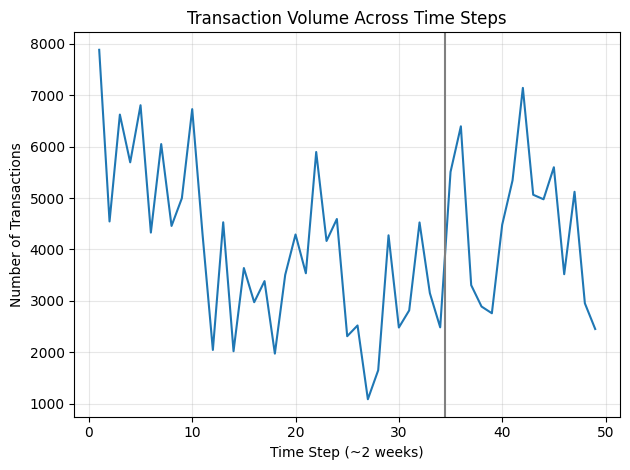

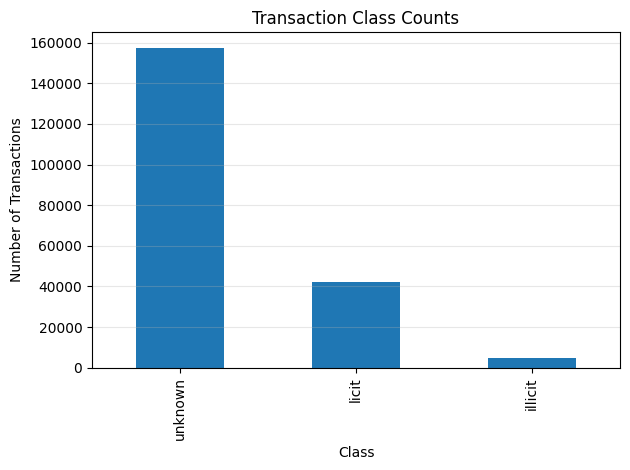

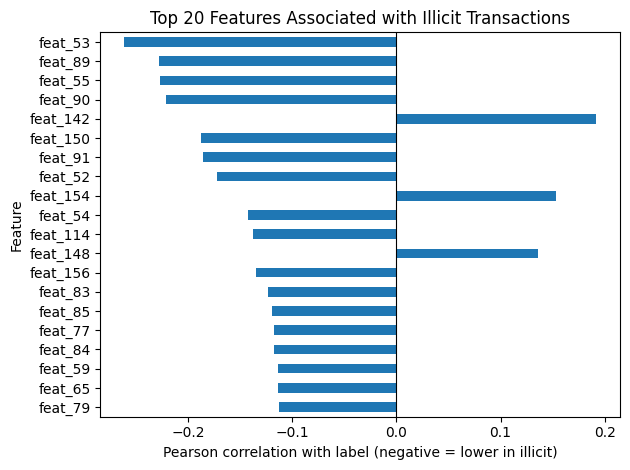

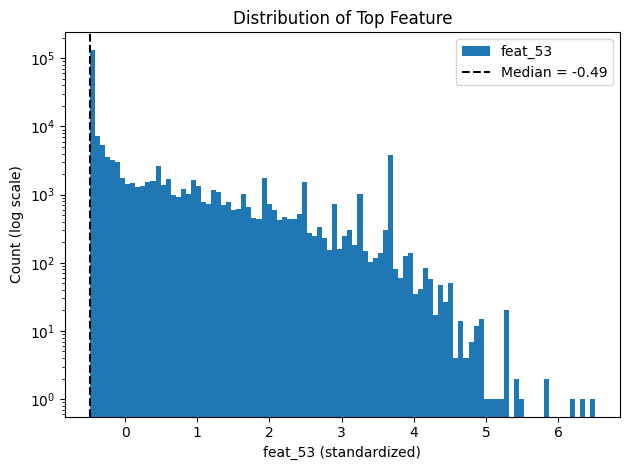

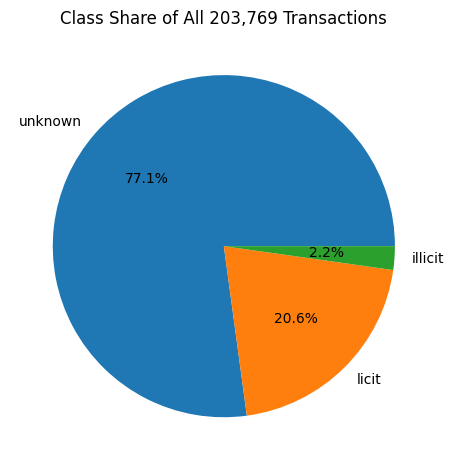

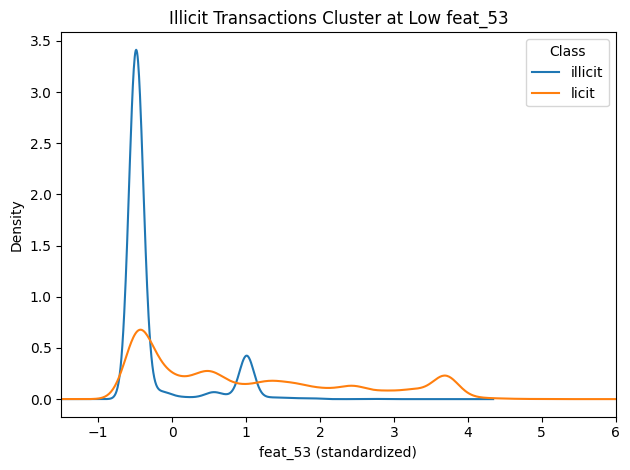

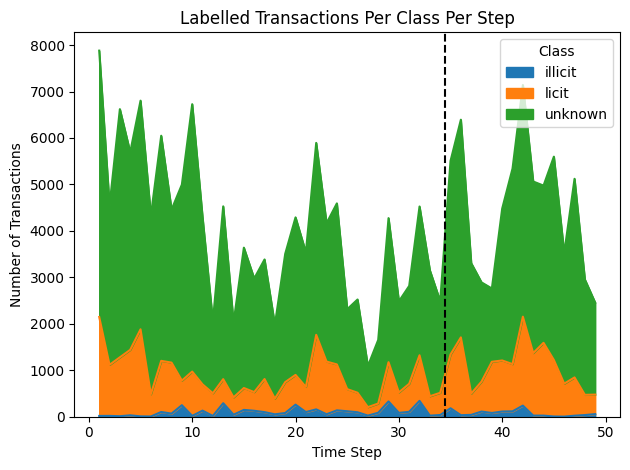

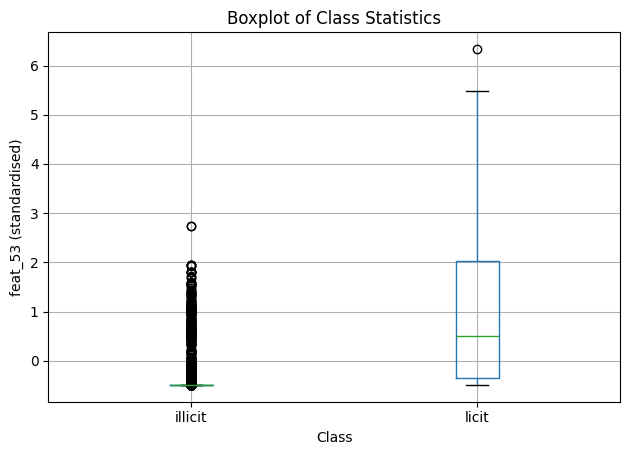

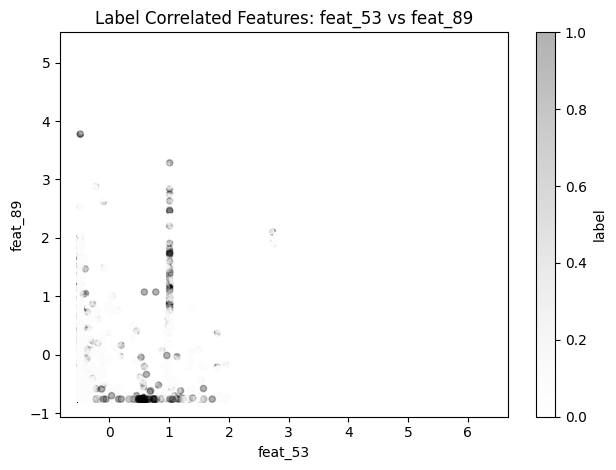

<Figure size 640x480 with 0 Axes>

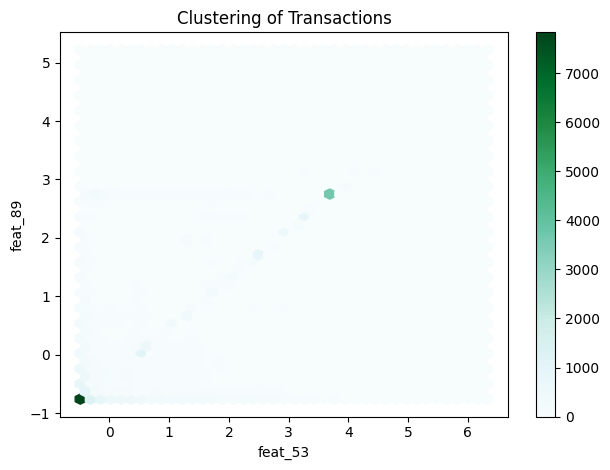

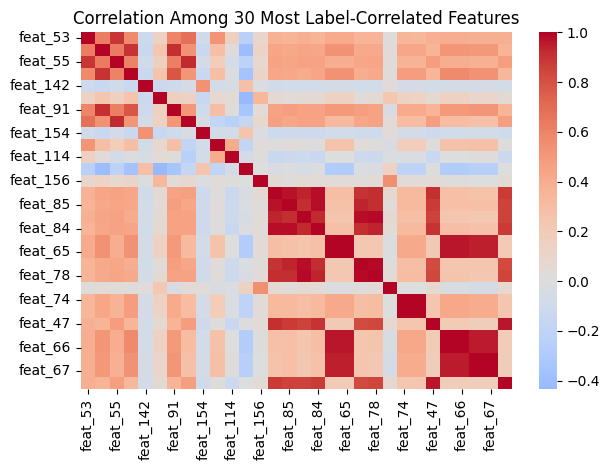

In [22]:
top = corr_label.index[0]; second = corr_label.index[1]

plt.figure() #Transactions per time step
timeSeries['n'].plot(kind='line')
plt.title('Transaction Volume Across Time Steps')
plt.xlabel('Time Step (~2 weeks)')
plt.ylabel('Number of Transactions')
plt.axvline(34.5, color = 'grey')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure() #Count per class 
df['class_name'].value_counts().plot(kind='bar')
plt.title('Transaction Class Counts')
plt.xlabel('Class')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure() #Top 20 features
corr_label.head(20).plot(kind='barh')
plt.title('Top 20 Features Associated with Illicit Transactions')
plt.xlabel('Pearson correlation with label (negative = lower in illicit)')
plt.ylabel('Feature')
plt.axvline(0, color = 'black', linewidth = 0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plt.figure() #Distribution of top feature
df[top].plot(kind='hist', bins=100)
plt.yscale('log')
plt.axvline(df[top].median(), color='black', linestyle='--', label=f'Median = {df[top].median():.2f}')
plt.title("Distribution of Top Feature")
plt.xlabel(f'{top} (standardized)')
plt.ylabel('Count (log scale)')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure() #Class share percentage
df['class_name'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title(f'Class Share of All {len(df):,} Transactions')
plt.ylabel('')
plt.tight_layout()
plt.show()

plt.figure() #Smoothed density of top feature
labeled.groupby('class_name')[top].plot(kind='kde', legend=True)
plt.xlim(-1.5, 6)
plt.title(f'Illicit Transactions Cluster at Low {top}')
plt.xlabel(f'{top} (standardized)')
plt.ylabel('Density')
plt.legend(title='Class')
plt.tight_layout()
plt.show()

#Counts per class per step
pd.crosstab(df['time_step'], df['class_name']).plot(kind='area')
plt.title('Labelled Transactions Per Class Per Step')
plt.xlabel('Time Step')
plt.ylabel('Number of Transactions')
plt.axvline(34.5, color='black', linestyle='--')
plt.legend(title='Class', loc='upper right')
plt.tight_layout()
plt.show()

#Top feature distribution
labeled.boxplot(column=top, by='class_name')
plt.suptitle('')
plt.title(f'Boxplot of Class Statistics')
plt.xlabel('Class')
plt.ylabel(f'{top} (standardised)')
plt.tight_layout()
plt.show()

#Top vs second feature, colored by label
labeled.plot(kind='scatter', x=top, y=second, c='label', alpha=0.3)
plt.title(f'Label Correlated Features: {top} vs {second}')
plt.xlabel(top)
plt.ylabel(second)
plt.tight_layout()
plt.show()

plt.figure() #Same pair, point density
labeled.plot(kind='hexbin', x=top, y=second, gridsize=40)
plt.title('Clustering of Transactions')
plt.xlabel(top)
plt.ylabel(second)
plt.tight_layout()
plt.show()

plt.figure() #Correlation matrix of 30 most label-correlated features
sns.heatmap(labeled[corr_label.index[:30]].corr(), cmap='coolwarm', center=0)
plt.title('Correlation Among 30 Most Label-Correlated Features')
plt.tight_layout()
plt.show()

In [26]:
import random

deg = pd.Series(dict(G.degree()))
comp_sizes = pd.Series([len(c) for c in nx.connected_components(G)])

random.seed(1242235)
sources = random.sample(list(G.nodes), 300)
path_lengths = pd.Series([d for s in sources for d in nx.single_source_shortest_path_length(G, s).values() if d > 0])

graph_summary = pd.Series({
    'Nodes': G.number_of_nodes(),
    'Edges': G.number_of_edges(),
    'Average Degree': deg.mean(),
    'Median Degree': deg.median(),
    'Max Degree': deg.max(),
    'Density': nx.density(G),
    'Average Clustering Coefficient': nx.average_clustering(G),
    'Global Clustering': nx.transitivity(G),
    'Connected Components': len(comp_sizes),
    'Largest Component (nodes)': comp_sizes.max(),
    'Smallest Component (nodes)': comp_sizes.min(),
    'Mean Shortest Path (sampled)': path_lengths.mean(),
    'Median Shortest Path (sampled)': path_lengths.median(),
    'Longest Shortest Path Seen (sampled)': path_lengths.max(),
}, name='value').to_frame()

display(graph_summary.style.format('{:,.10g}'))

,value
Nodes,"203,769"
Edges,"234,355"
Average Degree,2.30020268
Median Degree,2
Max Degree,473
Density,1.128834106e-05
Average Clustering Coefficient,0.01376219072
Global Clustering,0.01168697396
Connected Components,49
Largest Component (nodes),"7,880"
